# Probe the training paradigms

The algorithms (PPO, APPO, SAC) are RLlib's and trusted. What MARLEM adds, and
what this notebook checks, is the **training paradigm** around them: how each
agent's observation, action and reward reach the networks in DTDE (one module per
agent), CTCE (one central module) and CTDE (central training, per-agent acting
heads), how rewards are summed for the grouped paradigms, how episodes end, and
which networks training updates.

Method: Andy Jones's probe environments
([Debugging RL, Without the Agonizing Pain](https://andyljones.com/posts/rl-debugging.html)),
made multi-agent and continuous (`core/envs/probes.py`). Each probe adds one
piece of the learning problem and has an exact answer, so the first probe a
paradigm fails names the broken piece. After training, the learner's networks
are queried directly in the probe's states (`core/rl/probe.py`), instead of
reading a noisy return curve.

| Probe | Adds | Correct answer |
|---|---|---|
| 1 Constant | value loss, optimiser | value 1 per agent |
| 2 Observation | observation reaches the value | value = observation |
| 3 Discount | discounting, episode ends (γ = 0.5) | V(first step) = 0.5, V(last) = 1 |
| 4 Action | policy gradient, each agent's own reward | action = the agent's target (−0.6, 0, 0.6) |
| 5 Obs → action | policy uses the agent's observation | action = observation / 2 |
| 6 Agent order | probe 4 with agent names that sort differently | as probe 4 |

For the grouped paradigms the expected value is the sum over the agents (their
reward is the group's sum). Alongside, the learner's health metrics Jones
recommends watching: entropy, KL between old and new policy, explained variance
of the value function, and whether any loss became NaN.

Runs in this process (`build_local`), with the `marlem` conda env as kernel;
about 40 minutes for all paradigms.

The saved outputs leave out Ray's warnings (stderr): when a gradient becomes NaN, RLlib prints every affected tensor, which made this notebook 200 MB.

In [1]:
import math
import os
import sys
from pathlib import Path

# RL root; imports use its parent so market core/ stays separate.
ROOT = next(p / "RL" for p in [Path.cwd(), *Path.cwd().parents] if (p / "RL" / "core").is_dir())
sys.path.insert(0, str(ROOT.parent))
os.environ["PYTHONPATH"] = os.pathsep.join(filter(None, [str(ROOT.parent), os.environ.get("PYTHONPATH", "")]))  # Ray's worker processes import RL.core too

import matplotlib.pyplot as plt
import pandas as pd

from RL.core.envs.probes import ActionProbe, ConstantProbe, DiscountProbe, ObsActionProbe, ObservationProbe
from RL.core.rl.base import RLAlgorithm, TrainingMode
from RL.core.rl.probe import run_probe

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

ALGORITHM = RLAlgorithm.PPO
MODES = [TrainingMode.DTDE, TrainingMode.CTCE, TrainingMode.CTDE]
N_AGENTS = 3
# lr 3e-4 is the usual PPO setting; the original starts at 1e-5 and lets
# population-based training raise it. The rest of PPO's settings are the original's.
TRAINING = {"lr": 3e-4, "train_batch_size_per_learner": 1000}

# name, probe, env_config extras, iterations, training extras
PROBES = [
    ("1 Constant", ConstantProbe, {}, 10, {}),
    ("2 Observation", ObservationProbe, {}, 10, {}),
    ("3 Discount", DiscountProbe, {}, 10, {"gamma": 0.5}),
    ("4 Action", ActionProbe, {}, 20, {}),
    ("5 Obs -> action", ObsActionProbe, {}, 20, {}),
    ("6 Agent order", ActionProbe, {"scramble_ids": True}, 20, {}),
]

## Run every probe with every paradigm

Each run prints one line: whether the outputs pass, the largest error, and the
health metrics over training.

In [ ]:
def health(history: pd.DataFrame) -> dict:
    losses = history[["policy_loss", "vf_loss"]].astype(float)
    return {
        "nan loss": bool(losses.isna().any().any() or (~losses.map(math.isfinite)).any().any()),
        "entropy start": history.entropy.iloc[0],
        "entropy end": history.entropy.iloc[-1],
        "max kl": history.kl.astype(float).max(),
        "explained var end": history.vf_explained_var.iloc[-1],
    }


runs = {}
for name, probe, extra_env, iters, extra_training in PROBES:
    for mode in MODES:
        checks, history = run_probe(
            probe, mode, iters, {"n_agents": N_AGENTS, **extra_env}, ALGORITHM,
            **TRAINING, **extra_training,
        )
        runs[name, mode.value] = (checks, history)
        h = health(history)
        print(f"{name:16} {mode.value}: {'PASS' if checks.ok.all() else 'FAIL'}, "
              f"largest error {checks.error.abs().max():.3f}, nan loss {h['nan loss']}, "
              f"entropy {h['entropy start']:.2f} -> {h['entropy end']:.2f}, max kl {h['max kl']:.3g}")

2026-10-12 21:35:11,820	INFO worker.py:2012 -- Started a local Ray instance.
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
2026-10-12 21:35:13,762	WARNING algorithm_config.py:5053 -- You are running PPO on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be remov

1 Constant       dtde: PASS, largest error 0.000, nan loss False, entropy 1.28 -> 0.57, max kl 0.0308
1 Constant       ctce: PASS, largest error 0.002, nan loss False, entropy 3.86 -> 3.07, max kl 0.0284


c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

1 Constant       ctde: PASS, largest error 0.000, nan loss False, entropy 3.92 -> 3.96, max kl 0.03


c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

2 Observation    dtde: PASS, largest error 0.000, nan loss False, entropy 4.13 -> 21.42, max kl 8.9


## Summary

A cell passes when every checked output is within 0.15 of the correct answer
(values: 0.15 times the size of the answer). Read each column top to bottom: the
first failure is the piece to look at.

In [ ]:
summary = pd.DataFrame(
    {
        mode.value: {
            name: ("PASS" if runs[name, mode.value][0].ok.all() else "FAIL")
            + (" (nan)" if health(runs[name, mode.value][1])["nan loss"] else "")
            for name, *_ in PROBES
        }
        for mode in MODES
    }
)
summary

,dtde,ctce,ctde
1 Constant,PASS,PASS,PASS
2 Observation,PASS,PASS (nan),PASS
3 Discount,PASS,PASS,PASS
4 Action,PASS,FAIL,FAIL
5 Obs -> action,PASS,FAIL,FAIL
6 Agent order,PASS,PASS,FAIL


## Details

The outputs of every failing run, then the health metrics of every run.

In [ ]:
for (name, mode), (checks, history) in runs.items():
    if not checks.ok.all():
        print(f"--- {name}, {mode}")
        display(checks)

--- 4 Action, ctce


,state,output,expected,got,error,ok
0,obs 0,action agent_00,-0.6,-0.796,-0.196,False
1,obs 0,action agent_01,0.0,0.006,0.006,True
2,obs 0,action agent_02,0.6,0.726,0.126,True


--- 4 Action, ctde


,state,output,expected,got,error,ok
0,obs 0,action agent_00,-0.6,-0.013,0.587,False
1,obs 0,action agent_01,0.0,0.193,0.193,False
2,obs 0,action agent_02,0.6,0.109,-0.491,False


--- 5 Obs -> action, ctce


,state,output,expected,got,error,ok
0,all +1,action agent_00,0.5,0.591,0.091,True
1,all +1,action agent_01,0.5,0.675,0.175,False
2,all +1,action agent_02,0.5,0.494,-0.006,True
3,all -1,action agent_00,-0.5,-0.493,0.007,True
4,all -1,action agent_01,-0.5,-0.441,0.059,True
5,all -1,action agent_02,-0.5,-0.454,0.046,True
6,mixed,action agent_00,0.5,0.648,0.148,True
7,mixed,action agent_01,-0.5,-0.623,-0.123,True
8,mixed,action agent_02,0.5,0.431,-0.069,True


--- 5 Obs -> action, ctde


,state,output,expected,got,error,ok
0,all +1,action agent_00,0.5,0.027,-0.473,False
1,all +1,action agent_01,0.5,0.033,-0.467,False
2,all +1,action agent_02,0.5,-0.174,-0.674,False
3,all -1,action agent_00,-0.5,-0.163,0.337,False
4,all -1,action agent_01,-0.5,0.068,0.568,False
5,all -1,action agent_02,-0.5,-0.086,0.414,False
6,mixed,action agent_00,0.5,0.027,-0.473,False
7,mixed,action agent_01,-0.5,0.068,0.568,False
8,mixed,action agent_02,0.5,-0.174,-0.674,False


--- 6 Agent order, ctde


,state,output,expected,got,error,ok
0,obs 0,action agent_2,-0.6,-0.103,0.497,False
1,obs 0,action agent_10,0.0,-0.147,-0.147,True
2,obs 0,action agent_1,0.6,0.149,-0.451,False


In [ ]:
health_table = pd.DataFrame({key: health(history) for key, (_, history) in runs.items()}).T
health_table.index.names = ["probe", "paradigm"]
health_table

nan loss entropy start entropy end  max kl explained var end
probe           paradigm                                                             
1 Constant      dtde        False         1.459       0.717   0.027               0.0
                ctce        False         4.076       3.242   0.031               0.0
                ctde        False         4.137       4.222   0.038               0.0
2 Observation   dtde        False         4.191      21.419  10.027            -0.207
                ctce         True         4.122     147.903     inf            -0.437
                ctde        False         5.447     151.277     inf             0.234
3 Discount      dtde        False          2.54       1.794   1.129            -0.303
                ctce        False         4.359       3.524   0.039            -0.253
                ctde        False         4.665       4.651    0.03            -0.428
4 Action        dtde        False         1.185        -1.5   0.141               0.0
                ctce        False         4.064        0.07   0.124               0.0
                ctde        False         3.906       3.883   0.112               0.0
5 Obs -> action dtde        False         1.162      -1.509   0.177               0.0
                ctce        False         3.526      -0.385   0.125              -0.0
                ctde        False         3.706       3.731   0.129            -0.011
6 Agent order   dtde        False         1.125      -1.434   0.181               0.0
                ctce        False         3.921      -0.203   0.118               0.0
                ctde        False         3.808        3.82   0.097               0.0

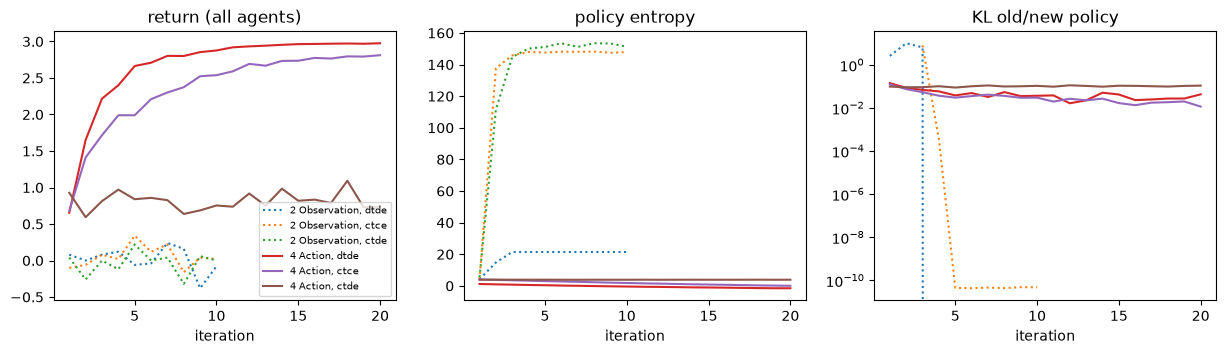

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for (name, mode), (_, history) in runs.items():
    if name in ("2 Observation", "4 Action"):
        style = "-" if name.startswith("4") else ":"
        axes[0].plot(history.index, history.return_mean, style, label=f"{name}, {mode}")
        axes[1].plot(history.index, history.entropy, style, label=f"{name}, {mode}")
        axes[2].plot(history.index, history.kl.astype(float), style, label=f"{name}, {mode}")
for ax, title in zip(axes, ("return (all agents)", "policy entropy", "KL old/new policy")):
    ax.set_title(title)
    ax.set_xlabel("iteration")
axes[2].set_yscale("log")
axes[0].legend(fontsize=7)
plt.show()